# ERA5 weather to capacity factors

This notebook walks the full garudata weather path: the ERA5 store, a lazy cutout
over it, the raw-to-canonical variable translation, PV and wind capacity factors, and
finally per-village hourly time series written as the CSV artifacts GARUDA consumes.
Everything runs on one real month — January 2023 over the NTT/Timor box — so the whole
notebook executes in well under a minute on a laptop, with no CDS credentials needed
(the month is already in the local store).

## 1. The weather store

garudata keeps ERA5 in a fixed, cluster-compatible layout:

```
<store_root>/era5/<config>/<year>/<month:02d>.nc
```

one netCDF file per calendar month. `download_era5_wind_solar` writes exactly this
layout (the same contract as the lab's shared `$GEODATA_ROOT` store), builds the CDS
`area` in the correct `[N, W, S, E]` order from canonical `(W, S, E, N)` bounds, and
downloads to a `.part` file that is atomically renamed only on success — an
interrupted run can never leave a truncated file at a final path.

The call below is **live**. Because `skip_existing=True` (the default) and January
2023 is already in `../validation/store`, it returns in milliseconds without touching
the network — this is exactly how a resumable multi-month download behaves when it is
re-run: finished months are skipped, only the gaps are fetched.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import garudata as gd
from garudata.profiles import indonesia as idn

STORE = "../validation/store"
print("NTT box (W, S, E, N):", idn.BBOX_NTT)

t0 = time.perf_counter()
paths = gd.weather.download_era5_wind_solar(
    years=[2023], months=[1], bounds_wsen=idn.BBOX_NTT, store_root=STORE,
)
elapsed_ms = (time.perf_counter() - t0) * 1000
for p in paths:
    print(f"{p}  ({p.stat().st_size / 1e6:.1f} MB)")
print(f"returned in {elapsed_ms:.1f} ms — file already in the store, so this was a no-op")

NTT box (W, S, E, N): (121.0, -11.0, 125.0, -8.5)
../validation/store/era5/wind_solar_hourly/2023/01.nc  (2.6 MB)
returned in 0.2 ms — file already in the store, so this was a no-op


A production run differs only in the arguments. A full year over the whole
captive-RE Indonesia domain, into the shared cluster store, looks like this
(roughly 2 GB for the year; re-running after an interruption picks up at the
first missing month):

```python
import os

gd.weather.download_era5_wind_solar(
    years=[2023],
    months=range(1, 13),
    bounds_wsen=idn.BBOX_INDONESIA,        # (95, -11, 141, 6)
    store_root=os.environ["GEODATA_ROOT"],  # shared cluster store
)
```

Requires `~/.cdsapirc` credentials; `cdsapi` is imported only when there is actual
work to do.

## 2. A lazy cutout

A `Cutout` is a lazy xarray view over whichever monthly files exist in the store,
subset to a bounding box — no gigabyte copies are materialized. Construction touches
no data; `.files` and `.missing()` report the store inventory for the request before
anything is opened.

In [2]:
cut = gd.cutout.Cutout(
    years=[2023], months=[1], bounds_wsen=idn.BBOX_NTT, store_root=STORE,
)
print(cut)
print("files:  ", [str(p) for p in cut.files])
print("missing:", cut.missing())

<garudata.Cutout config='wind_solar_hourly' years=[2023] months=[1] bounds_wsen=(121.0, -11.0, 125.0, -8.5) files=1/1 store='../validation/store'>
files:   ['../validation/store/era5/wind_solar_hourly/2023/01.nc']
missing: []


`.ds` opens the files with their **raw** CDS short names (coordinates are normalized
to `time`/`y`/`x` with `lon`/`lat` aliases, and ERA5's descending-latitude axis is
handled), while `.canonical()` applies the master-era raw-to-canonical variable
translation on top.

In [3]:
raw = cut.ds
print(f"grid: {raw.sizes['time']} hours x {raw.sizes['y']} lat x {raw.sizes['x']} lon cells")
print("raw CDS variables:", sorted(raw.data_vars))

grid: 744 hours x 11 lat x 17 lon cells
raw CDS variables: ['d2m', 'fdir', 'fsr', 'ro', 'sp', 'ssr', 'ssrd', 'stl4', 't2m', 'tisr', 'u100', 'v100', 'z']


The translation table below is the full raw-to-canonical mapping applied by
`.canonical()` — the same one the master-era pipeline uses, so downstream code never
sees CDS short names or accumulated-Joule units.

In [4]:
ds = cut.canonical()
print("canonical variables:", sorted(ds.data_vars))
print("influx_direct units:", ds["influx_direct"].attrs["units"])

pd.DataFrame(
    [
        ("fdir",       "influx_direct",        "renamed; clipped at 0, / 3600 -> W m-2"),
        ("ssrd, fdir", "influx_diffuse",       "ssrd - fdir; clipped at 0, / 3600 -> W m-2"),
        ("tisr",       "influx_toa",           "renamed; clipped at 0, / 3600 -> W m-2"),
        ("ssrd, ssr",  "albedo",               "(ssrd - ssr) / ssrd, guarded, clipped to [0, 1]"),
        ("u100, v100", "wnd100m",              "sqrt(u100**2 + v100**2)"),
        ("z",          "height",               "z / 9.80665 (time-invariant)"),
        ("t2m",        "temperature",          "renamed (K)"),
        ("d2m",        "dewpoint_temperature", "renamed (K)"),
        ("sp",         "pressure",             "renamed (Pa)"),
        ("stl4",       "soil temperature",     "renamed (K)"),
        ("fsr",        "roughness",            "renamed (m)"),
        ("ro",         "runoff",               "renamed"),
    ],
    columns=["raw input(s)", "canonical", "derivation"],
)

canonical variables: ['albedo', 'dewpoint_temperature', 'height', 'influx_diffuse', 'influx_direct', 'influx_toa', 'pressure', 'roughness', 'runoff', 'soil temperature', 'temperature', 'wnd100m']
influx_direct units: W m**-2


,raw input(s),canonical,derivation
0,fdir,influx_direct,"renamed; clipped at 0, / 3600 -> W m-2"
1,"ssrd, fdir",influx_diffuse,"ssrd - fdir; clipped at 0, / 3600 -> W m-2"
2,tisr,influx_toa,"renamed; clipped at 0, / 3600 -> W m-2"
3,"ssrd, ssr",albedo,"(ssrd - ssr) / ssrd, guarded, clipped to [0, 1]"
4,"u100, v100",wnd100m,sqrt(u100**2 + v100**2)
5,z,height,z / 9.80665 (time-invariant)
6,t2m,temperature,renamed (K)
7,d2m,dewpoint_temperature,renamed (K)
8,sp,pressure,renamed (Pa)
9,stl4,soil temperature,renamed (K)


Three derivations are worth spelling out. ERA5 hourly radiation variables
(`ssrd`, `fdir`, `tisr`) are **accumulated fluxes in J m⁻² per hour**, so the
canonical `influx_*` variables divide by 3600 to get mean W m⁻² for the hour (and
clip at zero first — tiny negative accumulations occur). `albedo` is derived as
`(ssrd − ssr) / ssrd`, i.e. reflected over downward shortwave, with a guard for
`ssrd ≤ 0` (night → 0) and a clip to [0, 1]. `wnd100m` is the scalar 100 m wind speed
`sqrt(u100² + v100²)`; the components are dropped once it exists. The translation is
idempotent — canonicalizing twice is a no-op.

## 3. Solar capacity factors

`pv_cf_ghi` is the transparent GHI-based model, bit-compatible with GARUDA's
reference tool (`tools/solar_resource_era5.py`): `CF = clip(GHI/1000, 0, 1) · PR ·
(1 + γ (T_cell − 25))` with an NOCT cell-temperature estimate. The result is a
`cf(time, y, x)` array in UTC; for the diurnal profile we bin by **local hour**
(WITA, UTC+8 — the NTT zone).

domain-mean CF: 0.186   diurnal peak at local hour 12 (CF 0.59)


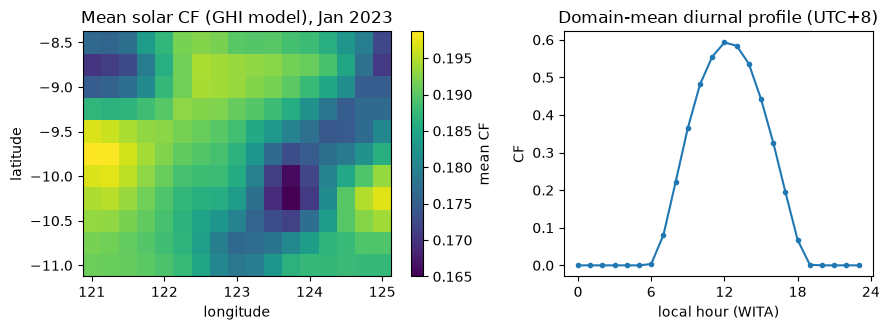

In [5]:
cf_ghi = gd.convert.pv_cf_ghi(ds)
WITA = idn.TZ_OFFSETS_HOURS["WITA"]

ts = cf_ghi.mean(["y", "x"])
local_hour = ((ts["time"].dt.hour + WITA) % 24).rename("local_hour")
diurnal = ts.groupby(local_hour).mean()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.4), gridspec_kw={"width_ratios": [1.25, 1]})
cf_ghi.mean("time").plot(ax=ax1, cmap="viridis", cbar_kwargs={"label": "mean CF"})
ax1.set(title="Mean solar CF (GHI model), Jan 2023", xlabel="longitude", ylabel="latitude")
ax2.plot(diurnal["local_hour"], diurnal, marker="o", ms=3)
ax2.set(title=f"Domain-mean diurnal profile (UTC+{WITA})", xlabel="local hour (WITA)", ylabel="CF")
ax2.set_xticks(range(0, 25, 6))
fig.tight_layout();

print(f"domain-mean CF: {float(cf_ghi.mean()):.3f}   "
      f"diurnal peak at local hour {int(diurnal.idxmax())} (CF {float(diurnal.max()):.2f})")

`pv_cf_poa` is the plane-of-array model (pvlib): per-cell solar position, DNI from
the ERA5 direct flux, isotropic-sky transposition to an equator-facing tilted panel,
then the same NOCT temperature derating.

**Note on `fdir`:** ERA5's `fdir` (canonical `influx_direct`) is a *horizontal*
direct flux, not DNI. garudata divides it by cos(solar zenith) — with a low-sun
guard (elevation ≳ 3°, else DNI = 0) — before handing it to pvlib. Passing
`fdir` directly as `dni` would apply the cosine twice and bias POA low.
The tilt defaults are hemisphere-aware (equator-facing, per grid cell), which
matters for a domain that sits south of the equator.

mean CF — POA: 0.179, GHI: 0.186; daylight correlation r = 0.999 (n = 81090)


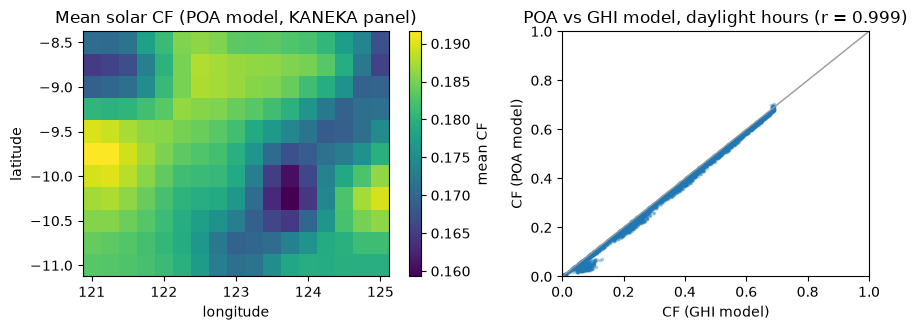

In [6]:
cf_poa = gd.convert.pv_cf_poa(ds, panel=idn.PANEL)

ghi_flat = cf_ghi.values.ravel()
poa_flat = cf_poa.values.ravel()
day = ghi_flat > 0  # daylight hours
r = np.corrcoef(ghi_flat[day], poa_flat[day])[0, 1]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.4), gridspec_kw={"width_ratios": [1.25, 1]})
cf_poa.mean("time").plot(ax=ax1, cmap="viridis", cbar_kwargs={"label": "mean CF"})
ax1.set(title=f"Mean solar CF (POA model, {idn.PANEL} panel)", xlabel="longitude", ylabel="latitude")

rng = np.random.default_rng(0)
sub = rng.choice(np.flatnonzero(day), size=4000, replace=False)
ax2.plot([0, 1], [0, 1], color="0.6", lw=1)
ax2.scatter(ghi_flat[sub], poa_flat[sub], s=3, alpha=0.25)
ax2.set(title=f"POA vs GHI model, daylight hours (r = {r:.3f})",
        xlabel="CF (GHI model)", ylabel="CF (POA model)", xlim=(0, 1), ylim=(0, 1))
fig.tight_layout();

print(f"mean CF — POA: {float(cf_poa.mean()):.3f}, GHI: {float(cf_ghi.mean()):.3f}; "
      f"daylight correlation r = {r:.3f} (n = {int(day.sum())})")

## 4. Wind capacity factors

`wind_cf` extrapolates the 100 m wind to hub height (log law, using the ERA5
`roughness` field) and passes it through the turbine power curve. The curve lookup
uses `np.interp(v, V, CF, left=0.0, right=0.0)`, so hours below cut-in and above
cut-out yield **exactly 0** — never an extrapolated (or, worse, −inf) value.

domain-mean wind CF: 0.202   (bounded: min 0.00, max 1.00)


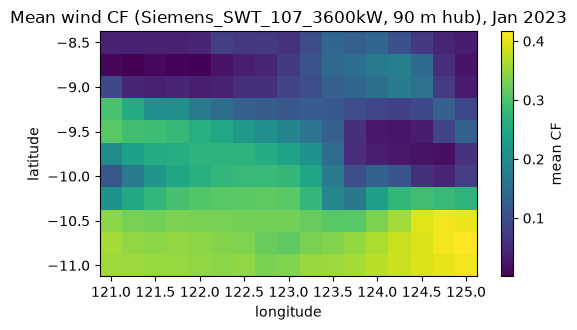

In [7]:
cf_wind = gd.convert.wind_cf(ds, turbine=idn.TURBINE, hub_height=90)

fig, ax = plt.subplots(figsize=(5.8, 3.4))
cf_wind.mean("time").plot(ax=ax, cmap="viridis", cbar_kwargs={"label": "mean CF"})
ax.set(title=f"Mean wind CF ({idn.TURBINE}, 90 m hub), Jan 2023",
       xlabel="longitude", ylabel="latitude")
fig.tight_layout();

print(f"domain-mean wind CF: {float(cf_wind.mean()):.3f}   "
      f"(bounded: min {float(cf_wind.min()):.2f}, max {float(cf_wind.max()):.2f})")

## 5. Village time series and GARUDA artifacts

`sample_points` turns the CF grid into per-point hourly series: it rolls the UTC
axis to local time (+8 h for WITA; the roll wraps at the series boundary, which is
the standard treatment in the reference tool), then takes the nearest grid cell to
each point. We use three Timor towns. Since `cf_ghi` is still in UTC, the shift
happens here — pass `utc_offset_hours=0` instead if the array was already shifted
(shifting twice corrupts the diurnal alignment).

In [8]:
villages = pd.DataFrame({
    "village": ["kupang", "soe", "atambua"],
    "lat": [-10.18, -9.86, -9.11],
    "lon": [123.58, 124.28, 124.89],
})
hourly = gd.writers.sample_points(
    cf_ghi, villages, utc_offset_hours=idn.TZ_OFFSETS_HOURS["WITA"],
)
hourly.head()

,village_kupang,village_soe,village_atambua
time,,,
2023-01-01 00:00:00,0.0,0.0,0.0
2023-01-01 01:00:00,0.0,0.0,0.0
2023-01-01 02:00:00,0.0,0.0,0.0
2023-01-01 03:00:00,0.0,0.0,0.0
2023-01-01 04:00:00,0.0,0.0,0.0


Averaging each local hour across the month gives the diurnal profile — a quick visual
check that the WITA shift landed correctly (solar noon should sit near local hour 12).

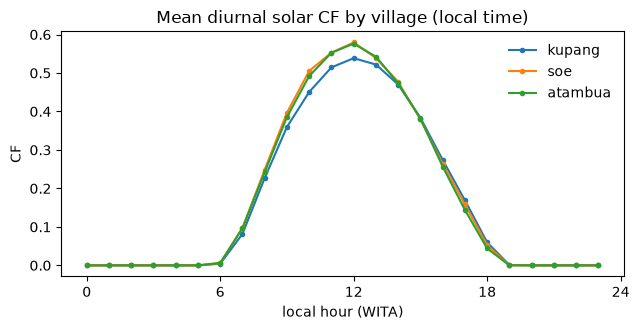

In [9]:
profile = hourly.groupby(hourly.index.hour).mean()

fig, ax = plt.subplots(figsize=(6.5, 3.4))
for col in profile.columns:
    ax.plot(profile.index, profile[col], marker="o", ms=3, label=col.removeprefix("village_"))
ax.set(title="Mean diurnal solar CF by village (local time)",
       xlabel="local hour (WITA)", ylabel="CF")
ax.set_xticks(range(0, 25, 6))
ax.legend(frameon=False)
fig.tight_layout();

`write_village_cf_hourly` emits the two CSVs downstream of this pipeline —
`village_solar_cf_hourly.csv` (a `time` column plus one `village_<id>` column per
point) and `village_solar_annual.csv` (`village, mean_cf, full_load_hours` with
FLH = mean CF × 8760). The row-count warning below is expected: a one-month demo has
744 hours, a production run covers a full year (8760 rows), and the annual file's
full-load hours annualize whatever period is supplied.

In [10]:
hourly_path, annual_path = gd.writers.write_village_cf_hourly(hourly, "_out/nb01")
print(hourly_path)
print(annual_path)

from IPython.display import display
display(pd.read_csv(hourly_path).head())
pd.read_csv(annual_path)

hourly CF table has 744 rows (expected 8760, or 8784 for a leap year)


_out/nb01/village_solar_cf_hourly.csv
_out/nb01/village_solar_annual.csv


,time,village_kupang,village_soe,village_atambua
0,2023-01-01 00:00:00,0.0,0.0,0.0
1,2023-01-01 01:00:00,0.0,0.0,0.0
2,2023-01-01 02:00:00,0.0,0.0,0.0
3,2023-01-01 03:00:00,0.0,0.0,0.0
4,2023-01-01 04:00:00,0.0,0.0,0.0


,village,mean_cf,full_load_hours
0,kupang,0.168981,1480.277758
1,soe,0.177330,1553.412606
2,atambua,0.174764,1530.934544


These two files are, column for column, exactly what GARUDA's
`tools/ntt/wire_era5_solar.py` consumes — point it at `_out/nb01/` and the village
solar supply side of the NTT model is wired to real ERA5 weather. The next notebook
picks up the land side: suitability rasters, per-cell suitable area, and siting.